# 02 - Baseline and model comparison

Owner: Nicolai. Interpretation: Philipp.

Compare a majority-class baseline, logistic regression and random forest using seven inputs. Sections 1-2 explain preprocessing; sections 3-5 run the fixed-configuration comparison on development data only.

**Scope:** five-fold validation on 800 development cases. No parameter search, threshold tuning, final model export or test evaluation. The 200 held-out test cases remain reserved for the final assessment.

## 1. Goal, assumptions, and experimental setup

The target is `bad_risk`: **0 = good risk; 1 = bad risk**. The fixed split contains 800 development cases and 200 test cases. Load only development data here.

Five stratified, shuffled folds (seed 42) compare models. Each round uses 640 training cases and 160 validation cases. Balanced accuracy is the provisional selection metric; bad-risk recall and error costs also matter. This cell selects the first fold to demonstrate preprocessing. Section 4 later trains and validates on all five folds.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import StratifiedKFold

ROOT = Path.cwd()
if not (ROOT / "code" / "preprocessing.py").exists():
    ROOT = ROOT.parent
if not (ROOT / "code" / "preprocessing.py").exists():
    raise FileNotFoundError("Run from the project directory or its notebooks directory.")
sys.path.insert(0, str(ROOT / "code"))

from preprocessing import NUMERIC_FEATURES, RANDOM_SEED, build_preprocessor, load_partition

X_dev, y_dev = load_partition()
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
training_rows, validation_rows = next(folds.split(X_dev, y_dev))
X_train, X_validation = X_dev.iloc[training_rows], X_dev.iloc[validation_rows]

print(f"Development: {len(X_dev)} cases with {X_dev.shape[1]} raw inputs")
print(f"Demonstration fold: {len(X_train)} training / {len(X_validation)} validation cases")
print("No test-partition analysis or classifier fitting in this demonstration.")

Development: 800 cases with 7 raw inputs
Demonstration fold: 640 training / 160 validation cases
No test-partition analysis or classifier fitting in this demonstration.


## 2. Data preprocessing

Shared factories live in `code/preprocessing.py`:

- **Five categorical inputs:** one-hot encoding creates a separate 0/1 column for each category observed in training. Codes such as A40 and A41 do not become a numerical ranking. Source categories such as A65 (unknown / no savings) remain valid categories.
- **Two numeric inputs:** standardize amount and duration for logistic regression using training means and standard deviations. Random forest keeps these numbers unscaled.
- **Unseen category:** `handle_unknown="ignore"` keeps the output shape stable and encodes that input's block as zeros. This does not teach the model the category's risk; a future demo should flag unsupported input categories.
- **Missing values:** the development-data review found none. No imputation, row deletion or feature removal is introduced.

In the example below, only the 640 training cases determine category columns and numeric scaling. Validation uses `transform`, never `fit`. More encoded columns do **not** mean more fields in the future seven-input demo.

In [2]:
# Logistic-regression variant: fit preprocessing on this training fold only.
preprocessor = build_preprocessor()
train_values = preprocessor.fit_transform(X_train)
scaler = preprocessor.named_transformers_["numeric"]
training_means = scaler.mean_.copy()
validation_values = preprocessor.transform(X_validation)

assert int(scaler.n_samples_seen_) == len(X_train)
np.testing.assert_allclose(training_means, X_train[NUMERIC_FEATURES].mean())
np.testing.assert_array_equal(scaler.mean_, training_means)
np.testing.assert_allclose(train_values[:, :2].mean(axis=0), 0, atol=1e-12)
assert train_values.shape[1] == validation_values.shape[1]

# Random-forest variant: encode categories, keep the two original numeric values.
tree_preprocessor = build_preprocessor(scale_numeric=False)
tree_train_values = tree_preprocessor.fit_transform(X_train)
tree_validation_values = tree_preprocessor.transform(X_validation)
np.testing.assert_array_equal(tree_train_values[:, :2], X_train[NUMERIC_FEATURES].to_numpy())
np.testing.assert_array_equal(tree_validation_values[:, :2], X_validation[NUMERIC_FEATURES].to_numpy())

print(f"Raw inputs: {X_train.shape[1]} -> encoded columns in this fold: {train_values.shape[1]}")
print(f"Training matrix: {train_values.shape}; validation matrix: {validation_values.shape}")
print(f"Scaler learned from {int(scaler.n_samples_seen_)} training cases only.")
display(pd.DataFrame({
    "input": NUMERIC_FEATURES,
    "training_mean": scaler.mean_,
    "training_standard_deviation": scaler.scale_,
}))
encoded_preview = pd.DataFrame(
    validation_values, columns=preprocessor.get_feature_names_out(), index=X_validation.index,
)
display(encoded_preview.head())

Raw inputs: 7 -> encoded columns in this fold: 31
Training matrix: (640, 31); validation matrix: (160, 31)
Scaler learned from 640 training cases only.


,input,training_mean,training_standard_deviation
0,credit_amount,3146.809375,2616.084874
1,duration_months,20.534375,11.712390


,numeric__credit_amount,numeric__duration_months,categorical__purpose_A40,categorical__purpose_A41,categorical__purpose_A410,categorical__purpose_A42,categorical__purpose_A43,categorical__purpose_A44,categorical__purpose_A45,categorical__purpose_A46,...,categorical__employment_duration_A71,categorical__employment_duration_A72,categorical__employment_duration_A73,categorical__employment_duration_A74,categorical__employment_duration_A75,categorical__credit_history_A30,categorical__credit_history_A31,categorical__credit_history_A32,categorical__credit_history_A33,categorical__credit_history_A34
row_id,,,,,,,,,,,,,,,,,,,,,
7,1.453007,1.320450,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
9,0.797830,0.808172,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
17,1.882657,0.808172,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
25,-0.677657,-1.240940,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
39,-1.027799,-0.984801,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


### How this connects to model training

This fitted preprocessor is a **single-fold teaching example**, not an artifact to reuse for the model comparison. Each validation round must learn its own transformations.

In the comparison below, `build_model_pipeline(model, scale_numeric=True)` combines a fresh preprocessor and a cloned, unfitted classifier. The shared comparison function receives **raw** development inputs and fits the entire scikit-learn pipeline separately inside each training fold. Use `scale_numeric=False` for random forest. Do not first transform all 800 development cases and then cross-validate those transformed values.

No fitted model is saved by this notebook. After model selection is frozen, the chosen complete pipeline will be refitted on all development cases and used for the final test and demo.

Implementation references: [scikit-learn preprocessing pitfalls](https://scikit-learn.org/stable/common_pitfalls.html), [OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html), and [ColumnTransformer](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html).

## 3. Majority-class baseline and fixed candidates

The baseline always predicts the most frequent training class (good risk). It represents a simple reference that ignores the applicant inputs. With the development class distribution, its expected accuracy is 70%, but its bad-risk recall is zero and balanced accuracy is 50%.

Before examining validation results, the first comparison uses these fixed choices:

| Candidate | Settings | Rationale |
| --- | --- | --- |
| Majority baseline | Most frequent training class | Check whether ML improves on a trivial rule |
| Logistic regression | C=1, lbfgs, maximum 2,000 iterations, balanced class weights | Simple regularized linear model; scale numeric inputs |
| Random forest | 300 trees, at least 5 training cases per leaf, balanced class weights, seed 42 | Allow nonlinear relationships while limiting very small leaves; keep numeric inputs unscaled |

Both ML models use inverse-frequency class weighting calculated inside the training fold. No resampling is used. Class weighting is a modeling choice, not a guarantee of calibration or fairness. These settings are not claimed to be optimal.

All candidates use a fixed bad-risk score threshold of **0.5**: scores at least 0.5 predict bad risk. Raw scores, especially after class weighting, should not be presented as calibrated future default probabilities. No thresholds or parameters are searched in this first comparison.

In [3]:
from train import candidate_pipelines, compare_models, save_comparison, summarize_folds

candidates = candidate_pipelines()
for name, pipeline in candidates.items():
    print(f"{name}: {pipeline.named_steps['model']}")
print("All candidates are unfitted here. The next cell runs the comparison.")

majority_baseline: DummyClassifier(strategy='most_frequent')
logistic_regression: LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42)
random_forest: RandomForestClassifier(class_weight='balanced', min_samples_leaf=5,
                       n_estimators=300, n_jobs=1, random_state=42)
All candidates are unfitted here. The next cell runs the comparison.


## 4. Compare all candidates on identical validation folds

For every model and fold, fit a fresh complete pipeline on 640 cases and predict the other 160. Each development case receives exactly one **out-of-fold** prediction per candidate: its prediction comes from a fit that excluded that case.

The summary reports means and sample standard deviations across five folds. These folds share training cases, so the standard deviation is a variability description, not a confidence interval or significance test. The primary metric is **balanced accuracy**, the average recall for the good and bad classes. Also inspect bad-risk precision/recall/F1 and ROC-AUC.

The same folds compare candidates, so selecting the best result can be optimistic. Final evidence must come from the reserved test set after decisions are frozen.

Model references: [LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html), [RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html), [balanced accuracy](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.balanced_accuracy_score.html).

In [4]:
fold_metrics, oof_predictions = compare_models(X_dev, y_dev)
summary = summarize_folds(fold_metrics)

assert len(fold_metrics) == 15  # three candidates, five folds
assert len(oof_predictions) == 3 * len(X_dev)
for name, rows in oof_predictions.groupby("model", sort=False):
    assert rows.row_id.is_unique
    assert set(rows.row_id) == set(X_dev.index)
assert (fold_metrics.training_cases == 640).all()
assert (fold_metrics.validation_cases == 160).all()

from evaluate import METRICS
readable_summary = summary[["model"]].copy()
for metric in METRICS:
    readable_summary[metric] = [
        f"{mean:.3f} +/- {std:.3f}"
        for mean, std in zip(summary[f"{metric}_mean"], summary[f"{metric}_std"])
    ]
display(readable_summary.set_index("model"))
print("Values are validation mean +/- sample standard deviation, not test scores.")

,accuracy,balanced_accuracy,bad_precision,bad_recall,bad_f1,roc_auc,cost_per_case
model,,,,,,,
majority_baseline,0.700 +/- 0.000,0.500 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000,0.500 +/- 0.000,1.500 +/- 0.000
logistic_regression,0.708 +/- 0.041,0.709 +/- 0.048,0.510 +/- 0.047,0.713 +/- 0.094,0.593 +/- 0.057,0.766 +/- 0.050,0.637 +/- 0.138
random_forest,0.703 +/- 0.036,0.702 +/- 0.054,0.501 +/- 0.043,0.700 +/- 0.104,0.583 +/- 0.065,0.778 +/- 0.040,0.657 +/- 0.157


Values are validation mean +/- sample standard deviation, not test scores.


## 5. Errors, illustrative costs and reusable outputs

For this historical label convention:

- **False approval:** actual bad risk predicted good (false negative). Illustrative cost: 5 units.
- **False rejection:** actual good risk predicted bad (false positive). Illustrative cost: 1 unit.
- Correct predictions cost zero. Cost per case = `(5 * false approvals + false rejections) / cases`.

These units come from the source's illustrative cost matrix, not monetary bank losses. For the always-good reference, the cost is 1.5 units per development case. A lower validation cost under this assumption does not establish profitability.

Confusion matrices below pool the 800 out-of-fold predictions per candidate. Fold means above and pooled metrics are different summaries; pooled ROC-AUC in particular can differ from the mean of fold ROC-AUCs. The JSON keeps both with explicit names.

Save CSVs, provenance and two figures for the report and presentation. No trained pipeline is exported yet.

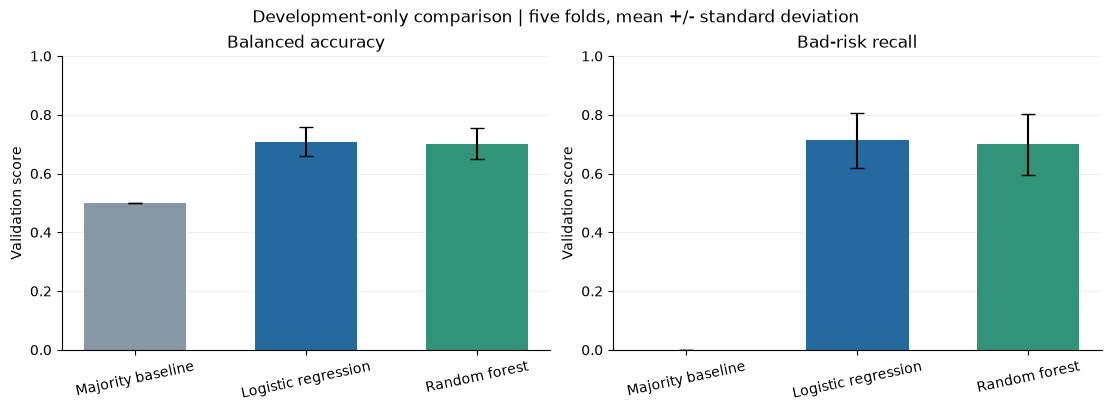

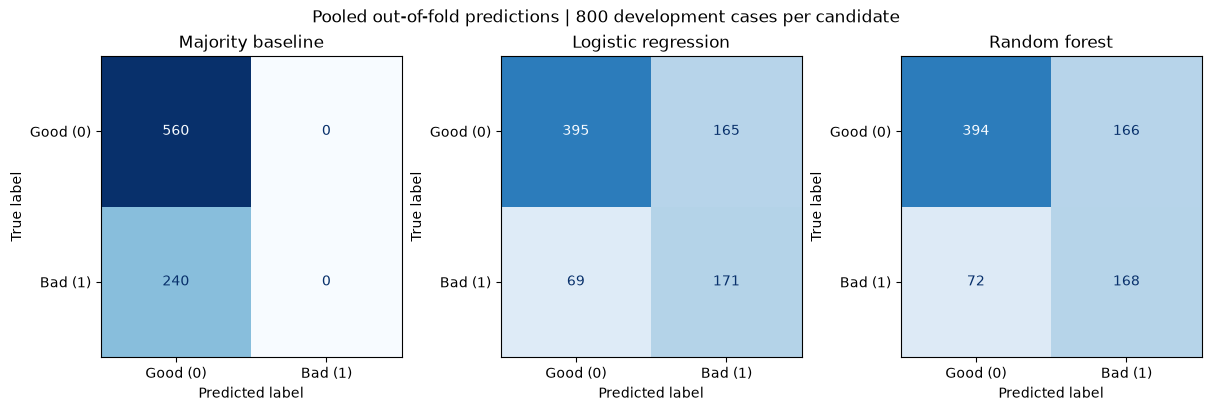

,false_approvals,false_rejections,illustrative_cost_units
model,,,
majority_baseline,240,0,1200
logistic_regression,69,165,510
random_forest,72,166,526


Saved validation outputs only. Test evaluation and final model export remain pending.


In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

save_comparison(fold_metrics, oof_predictions)
figure_dir = ROOT / "results" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)
labels = ["Majority baseline", "Logistic regression", "Random forest"]
colors = ["#8797a4", "#246a9f", "#319378"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for ax, metric, title in zip(axes, ["balanced_accuracy", "bad_recall"],
                           ["Balanced accuracy", "Bad-risk recall"]):
    ax.bar(labels, summary[f"{metric}_mean"], yerr=summary[f"{metric}_std"],
           color=colors, capsize=5, width=.6)
    ax.set(title=title, ylim=(0, 1), ylabel="Validation score")
    ax.tick_params(axis="x", labelrotation=12)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=.2)
    ax.set_axisbelow(True)
fig.suptitle("Development-only comparison | five folds, mean +/- standard deviation")
fig.savefig(figure_dir / "cv_model_comparison.png", dpi=160)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout="constrained")
pooled_errors = []
for ax, (name, rows), label in zip(axes, oof_predictions.groupby("model", sort=False), labels):
    matrix = confusion_matrix(rows.actual_bad_risk, rows.predicted_bad_risk, labels=[0, 1])
    ConfusionMatrixDisplay(matrix, display_labels=["Good (0)", "Bad (1)"]).plot(
        ax=ax, colorbar=False, cmap="Blues", values_format="d", im_kw={"vmin": 0, "vmax": 560},
    )
    ax.set_title(label)
    pooled_errors.append({"model": name, "false_approvals": int(matrix[1, 0]),
                          "false_rejections": int(matrix[0, 1]),
                          "illustrative_cost_units": int(5 * matrix[1, 0] + matrix[0, 1])})
fig.suptitle("Pooled out-of-fold predictions | 800 development cases per candidate")
fig.savefig(figure_dir / "cv_confusion_matrices.png", dpi=160)
plt.show()
display(pd.DataFrame(pooled_errors).set_index("model"))
print("Saved validation outputs only. Test evaluation and final model export remain pending.")

### Interpretation and next decision

- **Accuracy is insufficient:** the always-good baseline reaches 70% accuracy but detects no bad risks. Its balanced accuracy is 0.500.
- **Both ML models detect bad risks:** logistic regression finds 171/240 (71.25%) and random forest 168/240 (70%) in pooled out-of-fold predictions. They also falsely flag 165/560 and 166/560 good risks, respectively. Only about half of the flagged cases are truly labeled bad.
- **The primary metric slightly favors logistic regression:** mean balanced accuracy is 0.709 +/- 0.048, versus 0.702 +/- 0.054 for the forest. The forest has slightly higher mean ROC-AUC (0.778 versus 0.766). These small differences do not establish reliable superiority; fold variation is not a significance test.
- **Costs depend on assumptions:** the 5:1 illustration gives 510 total units for logistic regression, 526 for the forest, and 1,200 for the baseline. This is not currency or evidence of realized profitability.
- **Provisional next choice:** logistic regression is a reasonable simple candidate, given its primary-metric result. No final selection is frozen here. Review the error tradeoff and decide whether limited additional development-only tuning is necessary; record any later trials.

Before final testing, freeze the feature list, preprocessing, model settings and threshold. Then refit the chosen complete pipeline on all 800 development cases and evaluate once on the 200 reserved test cases. The present notebook neither performs that step nor exports a final fitted model. Raw scores are not calibrated future default probabilities, and this historical experiment does not demonstrate fairness or suitability for real lending.